<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/Tugas1_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Instalasi Library
Instal ANNOY, FAISS CPU, dan hnswlib.

In [1]:
!pip install -q annoy faiss-cpu hnswlib pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Import Library dan Konfigurasi
Gunakan `n_queries=100` untuk mengukur waktu pencarian dari sekumpulan query, bukan hanya satu query. Nilai `k=10` berarti setiap algoritma mencari 10 tetangga.

In [2]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import faiss
import hnswlib
from annoy import AnnoyIndex

SEED = 42
K = 10
N_QUERIES = 100
N_TREES = 10
NPROBE = 10
HNSW_M = 16
HNSW_EF_CONSTRUCTION = 200
HNSW_EF_SEARCH = 100

print('FAISS:', getattr(faiss, '__version__', 'versi tidak diketahui'))
print('Konfigurasi: k =', K, '| jumlah query =', N_QUERIES)

FAISS: 1.15.1
Konfigurasi: k = 10 | jumlah query = 100


## 3. Fungsi Persiapan Data
Data dibuat secara acak dan bertipe `float32`. Untuk metrik Cosine, database dan query dinormalisasi menjadi vektor satuan. Dengan demikian, FAISS dapat menggunakan inner product untuk menghasilkan urutan yang sama dengan cosine similarity. Ground truth dihitung menggunakan FAISS exact search.

In [3]:
def normalize_rows(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True)
    return x / np.maximum(norms, 1e-12)

def make_dataset(n_data, dim, seed=SEED):
    rng = np.random.default_rng(seed + n_data + dim)
    xb = rng.random((n_data, dim), dtype=np.float32)
    xq = rng.random((N_QUERIES, dim), dtype=np.float32)
    return xb, xq

def prepare_metric_data(xb, xq, metric):
    if metric == 'cosine':
        return normalize_rows(xb.copy()), normalize_rows(xq.copy())
    return xb, xq

## 4. Fungsi Ground Truth dan Recall@10
Ground truth merupakan 10 tetangga terdekat yang dihitung menggunakan pencarian exact FAISS. Recall@10 mengukur proporsi tetangga yang ditemukan algoritma ANN dan juga terdapat pada hasil exact. Nilai mendekati 1 menunjukkan hasil ANN semakin sesuai dengan ground truth.

In [4]:
def build_ground_truth(xb, xq, metric, k=K):
    dim = xb.shape[1]
    if metric == 'euclidean':
        exact = faiss.IndexFlatL2(dim)
    elif metric == 'cosine':
        exact = faiss.IndexFlatIP(dim)
    else:
        raise ValueError('Metrik tidak dikenali')
    exact.add(xb)
    _, gt = exact.search(xq, k)
    return gt

def recall_at_k(predicted, ground_truth, k=K):
    total = 0
    for pred, truth in zip(predicted, ground_truth):
        total += len(set(pred[:k]) & set(truth[:k]))
    return total / (len(ground_truth) * k)

## 5. Fungsi Benchmark ANNOY
Untuk Euclidean digunakan `euclidean`; untuk Cosine digunakan `angular`. Waktu pembangunan mencakup penambahan item dan pembuatan tree. Waktu query mencakup pencarian pada seluruh query dan dilaporkan sebagai rata-rata ms/query.

In [5]:
def benchmark_annoy(xb, xq, metric, gt):
    dim = xb.shape[1]
    annoy_metric = 'euclidean' if metric == 'euclidean' else 'angular'
    index = AnnoyIndex(dim, annoy_metric)

    t0 = time.perf_counter()
    for i in range(len(xb)):
        index.add_item(i, xb[i].tolist())
    index.build(N_TREES)
    build_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    labels = [index.get_nns_by_vector(q.tolist(), K) for q in xq]
    query_seconds = time.perf_counter() - t0
    labels = np.asarray(labels, dtype=np.int64)
    return {
        'Metode': 'ANNOY',
        'Build time (s)': build_seconds,
        'Query time (ms/query)': query_seconds * 1000 / len(xq),
        'Recall@10': recall_at_k(labels, gt)
    }

## 6. Fungsi Benchmark FAISS IVF
FAISS menggunakan `IndexIVFFlat`. Untuk Euclidean digunakan squared L2; untuk Cosine, vektor telah dinormalisasi dan pencarian menggunakan inner product. `nlist` ditentukan berdasarkan ukuran data dan `nprobe` mengatur jumlah cluster yang diperiksa. Build time mencakup training dan penambahan data.

In [6]:
def benchmark_faiss_ivf(xb, xq, metric, gt):
    n_data, dim = xb.shape
    nlist = 10 if n_data <= 1000 else 100
    quantizer = (faiss.IndexFlatL2(dim) if metric == 'euclidean'
                 else faiss.IndexFlatIP(dim))
    metric_type = faiss.METRIC_L2 if metric == 'euclidean' else faiss.METRIC_INNER_PRODUCT
    index = faiss.IndexIVFFlat(quantizer, dim, nlist, metric_type)

    t0 = time.perf_counter()
    index.train(xb)
    index.add(xb)
    build_seconds = time.perf_counter() - t0
    index.nprobe = min(NPROBE, nlist)

    t0 = time.perf_counter()
    _, labels = index.search(xq, K)
    query_seconds = time.perf_counter() - t0
    return {
        'Metode': 'FAISS IVF',
        'Build time (s)': build_seconds,
        'Query time (ms/query)': query_seconds * 1000 / len(xq),
        'Recall@10': recall_at_k(labels, gt)
    }

## 7. Fungsi Benchmark HNSW
HNSW menggunakan `l2` untuk Euclidean dan `cosine` untuk Cosine. Parameter `M`, `ef_construction`, dan `ef` ditetapkan sama pada seluruh konfigurasi agar perbandingan lebih konsisten. Build time mencakup inisialisasi dan penambahan data.

In [7]:
def benchmark_hnsw(xb, xq, metric, gt):
    dim = xb.shape[1]
    space = 'l2' if metric == 'euclidean' else 'cosine'
    index = hnswlib.Index(space=space, dim=dim)

    t0 = time.perf_counter()
    index.init_index(max_elements=len(xb), ef_construction=HNSW_EF_CONSTRUCTION,
                     M=HNSW_M)
    index.add_items(xb)
    build_seconds = time.perf_counter() - t0
    index.set_ef(HNSW_EF_SEARCH)

    t0 = time.perf_counter()
    labels, _ = index.knn_query(xq, k=K)
    query_seconds = time.perf_counter() - t0
    return {
        'Metode': 'HNSW',
        'Build time (s)': build_seconds,
        'Query time (ms/query)': query_seconds * 1000 / len(xq),
        'Recall@10': recall_at_k(labels, gt)
    }

## 8. Menjalankan Seluruh Eksperimen
Sel berikut menjalankan kombinasi 4 ukuran data/dimensi × 2 metrik × 3 algoritma sehingga menghasilkan 24 baris hasil. Untuk konfigurasi 1.000.000 data, proses pembangunan indeks dapat membutuhkan waktu cukup lama dan RAM besar. Jalankan pada runtime dengan memori yang memadai.

In [8]:
experiments = [
    (1_000, 2),
    (1_000, 5),
    (1_000_000, 2),
    (1_000_000, 5)
]
metrics = ['euclidean', 'cosine']
all_results = []

for n_data, dim in experiments:
    for metric in metrics:
        print(f'\nEksperimen: {n_data:,} data | {dim}D | {metric}')
        xb_raw, xq_raw = make_dataset(n_data, dim)
        xb, xq = prepare_metric_data(xb_raw, xq_raw, metric)
        gt = build_ground_truth(xb, xq, metric)

        for benchmark in [benchmark_annoy, benchmark_faiss_ivf, benchmark_hnsw]:
            result = benchmark(xb, xq, metric, gt)
            result.update({'Jumlah data': n_data, 'Dimensi': f'{dim}D', 'Metrik': metric})
            all_results.append(result)
            print(f"{result['Metode']}: build={result['Build time (s)']:.3f}s, "
                  f"query={result['Query time (ms/query)']:.4f}ms, "
                  f"recall={result['Recall@10']:.4f}")

        del xb_raw, xq_raw, xb, xq, gt


Eksperimen: 1,000 data | 2D | euclidean
ANNOY: build=0.027s, query=0.0242ms, recall=0.9960
FAISS IVF: build=0.001s, query=0.0094ms, recall=1.0000
HNSW: build=0.053s, query=0.0196ms, recall=1.0000

Eksperimen: 1,000 data | 2D | cosine
ANNOY: build=0.039s, query=0.0220ms, recall=0.9970
FAISS IVF: build=0.001s, query=0.0115ms, recall=1.0000
HNSW: build=0.045s, query=0.0158ms, recall=1.0000

Eksperimen: 1,000 data | 5D | euclidean
ANNOY: build=0.023s, query=0.0223ms, recall=0.9620
FAISS IVF: build=0.001s, query=0.0094ms, recall=1.0000
HNSW: build=0.061s, query=0.0322ms, recall=1.0000

Eksperimen: 1,000 data | 5D | cosine
ANNOY: build=0.026s, query=0.0225ms, recall=0.9820
FAISS IVF: build=0.001s, query=0.0126ms, recall=1.0000
HNSW: build=0.061s, query=0.0253ms, recall=1.0000

Eksperimen: 1,000,000 data | 2D | euclidean
ANNOY: build=27.684s, query=0.0579ms, recall=0.9950
FAISS IVF: build=0.272s, query=0.6438ms, recall=1.0000
HNSW: build=109.721s, query=0.0368ms, recall=1.0000

Eksperimen: 1

## 9. Tabel Hasil Perbandingan
Tabel pertama menampilkan seluruh hasil eksperimen. Tabel kedua menyusun hasil menurut konfigurasi data dan metrik sehingga mudah dipindahkan ke laporan tugas.

In [9]:
results_df = pd.DataFrame(all_results)
display(results_df.sort_values(['Jumlah data', 'Dimensi', 'Metrik', 'Metode']))

,Metode,Build time (s),Query time (ms/query),Recall@10,Jumlah data,Dimensi,Metrik
3,ANNOY,0.038897,0.021989,0.997,1000,2D,cosine
4,FAISS IVF,0.001127,0.011520,1.000,1000,2D,cosine
5,HNSW,0.044810,0.015843,1.000,1000,2D,cosine
0,ANNOY,0.027019,0.024231,0.996,1000,2D,euclidean
1,FAISS IVF,0.001072,0.009406,1.000,1000,2D,euclidean
2,HNSW,0.053339,0.019569,1.000,1000,2D,euclidean
9,ANNOY,0.026093,0.022540,0.982,1000,5D,cosine
10,FAISS IVF,0.001245,0.012625,1.000,1000,5D,cosine
11,HNSW,0.060595,0.025298,1.000,1000,5D,cosine
6,ANNOY,0.022698,0.022320,0.962,1000,5D,euclidean


In [10]:
# Tabel ringkas sesuai format tugas
summary_df = results_df.copy()
summary_df['Konfigurasi'] = (
    summary_df['Jumlah data'].map(lambda x: f'{x:,}') + '/' + summary_df['Dimensi']
    + ' - ' + summary_df['Metrik']
)
summary_table = summary_df.pivot_table(
    index='Konfigurasi', columns='Metode',
    values=['Build time (s)', 'Query time (ms/query)', 'Recall@10'],
    aggfunc='first'
)
display(summary_table)

Build time (s)                        \
Metode                            ANNOY FAISS IVF        HNSW   
Konfigurasi                                                     
1,000,000/2D - cosine         85.305755  0.444024  157.273454   
1,000,000/2D - euclidean      27.683596  0.271901  109.721427   
1,000,000/5D - cosine         28.159987  0.349108  161.645631   
1,000,000/5D - euclidean      20.621546  0.196958  173.899789   
1,000/2D - cosine              0.038897  0.001127    0.044810   
1,000/2D - euclidean           0.027019  0.001072    0.053339   
1,000/5D - cosine              0.026093  0.001245    0.060595   
1,000/5D - euclidean           0.022698  0.001025    0.061441   

                         Query time (ms/query)                     Recall@10  \
Metode                                   ANNOY FAISS IVF      HNSW     ANNOY   
Konfigurasi                                                                    
1,000,000/2D - cosine                 0.055835  0.929836  0.074367     0.157   
1,000,000/2D - euclidean              0.057921  0.643800  0.036817     0.995   
1,000,000/5D - cosine                 0.060097  0.975943  0.062043     0.981   
1,000,000/5D - euclidean              0.059677  0.719771  0.066459     0.950   
1,000/2D - cosine                     0.021989  0.011520  0.015843     0.997   
1,000/2D - euclidean                  0.024231  0.009406  0.019569     0.996   
1,000/5D - cosine                     0.022540  0.012625  0.025298     0.982   
1,000/5D - euclidean                  0.022320  0.009448  0.032183     0.962   

                                           
Metode                   FAISS IVF   HNSW  
Konfigurasi                                
1,000,000/2D - cosine        0.982  0.022  
1,000,000/2D - euclidean     1.000  1.000  
1,000,000/5D - cosine        1.000  1.000  
1,000,000/5D - euclidean     1.000  1.000  
1,000/2D - cosine            1.000  1.000  
1,000/2D - euclidean         1.000  1.000  
1,000/5D - cosine            1.000  1.000  
1,000/5D - euclidean         1.000  1.000

## 10. Visualisasi Hasil
Grafik berikut membandingkan query time dan Recall@10 untuk setiap algoritma. Grafik dipisahkan berdasarkan metrik agar hasil Euclidean dan Cosine tidak tercampur.

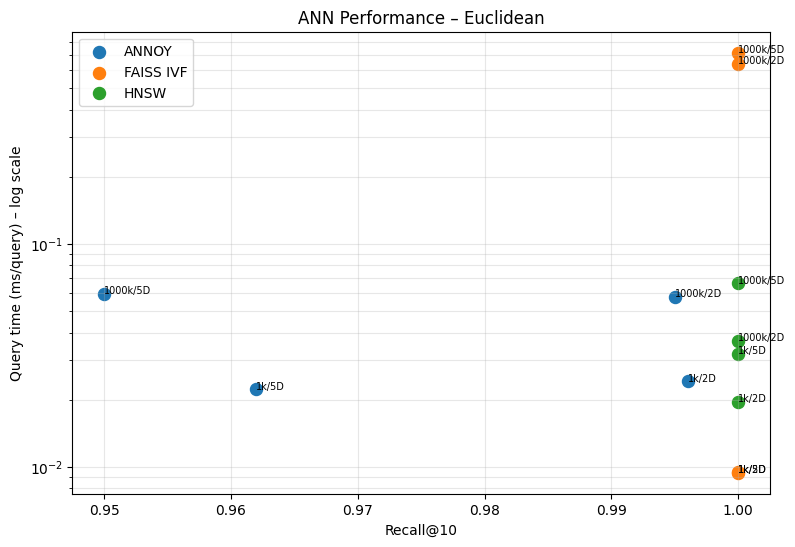

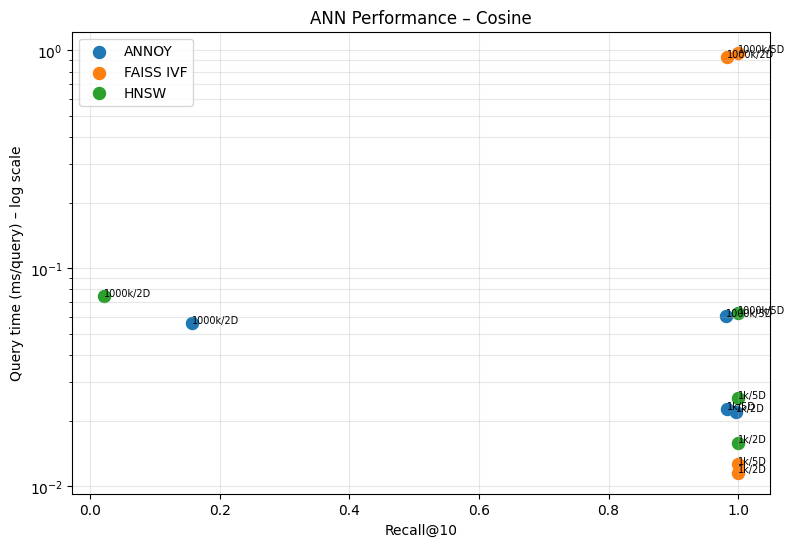

In [11]:
for metric in metrics:
    subset = results_df[results_df['Metrik'] == metric]
    plt.figure(figsize=(9, 6))
    for method in ['ANNOY', 'FAISS IVF', 'HNSW']:
        part = subset[subset['Metode'] == method]
        labels = part['Jumlah data'].map(lambda n: f'{n:,}') + '/' + part['Dimensi']
        plt.scatter(part['Recall@10'], part['Query time (ms/query)'], label=method, s=75)
        for _, row in part.iterrows():
            plt.annotate(f"{row['Jumlah data']//1000 if row['Jumlah data'] >= 1000 else row['Jumlah data']}k/{row['Dimensi']}",
                         (row['Recall@10'], row['Query time (ms/query)']), fontsize=7)
    plt.yscale('log')
    plt.xlabel('Recall@10')
    plt.ylabel('Query time (ms/query) – log scale')
    plt.title(f'ANN Performance – {metric.capitalize()}')
    plt.legend()
    plt.grid(True, which='both', alpha=0.3)
    plt.show()

## 11. Kesimpulan

Berdasarkan eksperimen, performa ANNOY, FAISS IVF, dan HNSW menunjukkan perbedaan pada waktu pembangunan indeks, waktu pencarian, dan Recall@10. Perubahan ukuran data, dimensi, serta metrik jarak dapat memengaruhi performa masing-masing algoritma. Algoritma terbaik ditentukan berdasarkan hasil pengukuran aktual dan kebutuhan aplikasi, bukan hanya berdasarkan satu parameter.

## Catatan Metodologi Penting
- Ground truth dibuat dengan FAISS exact search: `IndexFlatL2` untuk Euclidean dan `IndexFlatIP` pada vektor ternormalisasi untuk Cosine.
- Untuk Cosine, ANNOY memakai `angular`, yang mempertahankan urutan tetangga cosine; HNSW memakai `cosine`.
- FAISS menggunakan IVF approximate, bukan `IndexFlat`, agar pembandingan mencakup pencarian ANN. Proses training FAISS dimasukkan dalam build time.
- Build time ANNOY mencakup `add_item` dan `build`; HNSW mencakup inisialisasi dan `add_items`; FAISS IVF mencakup `train` dan `add`.
- Query time merupakan rata-rata waktu pencarian 100 query. Pembuatan ground truth tidak dihitung sebagai query time algoritma.
- Hasil waktu dapat bervariasi karena spesifikasi CPU, RAM, versi library, dan kondisi runtime.
- Untuk eksperimen yang lebih kuat, ulangi setiap konfigurasi minimal tiga kali dan laporkan rata-rata serta simpangan baku.